# The Forecasting Mistake That Fakes Good Results

## The test said "much better than the baseline". Real life said "worse".

![Two bars: the shuffled test says the model beats the baseline, the honest test says it does not](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/04-data-leakage/figures/fig_title.png)

*Shorter bar = smaller error. Same model, same data, two ways of testing it.*

Today: four ways to cheat **without knowing it**, and how to catch every one.

**Forecasting Made Easy, Episode 4** · Richel Attafuah, GStat

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RichelCode/Youtube/blob/main/forecasting-made-easy/04-data-leakage/data_leakage.ipynb)

# What you will learn today

1. What **data leakage** is, in plain words
2. Why it is so dangerous: it makes your score **better**, not worse
3. **Four leaks**, each shown in Python on real data
4. The **one question** that catches almost every leak
5. A **checklist** to run before you trust any forecast score

# What is data leakage?

**Data leakage** = your model uses information during testing that it **would not have** when making a real forecast.

**In plain words:** it is like a student who saw the exam answers.

- In the classroom: an excellent score
- In real life: the student cannot actually do the work

**The score is real. The skill is not.**

# Why it is so dangerous

- Most mistakes make your score **worse**, so you notice them
- Leakage makes your score **better**, so you **celebrate** instead
- You only find out **after** you use the model for real, when the forecasts are much worse than promised

**In plain words:** a broken scale that always shows 5 kg less. Nobody complains, until the doctor's visit.

# Today's experiment

- **Data:** the same Seattle bike counts as Episode 3 (daily, January 2023 to September 2026)
- **The task:** forecast each day's bikes **one week ahead**. Every Monday, we forecast next Monday
- **The model:** **gradient boosting**, a popular machine learning model. It builds many small decision trees, each one fixing the mistakes of the trees before it
- **The test period:** April to September 2026

**The rule:** a feature is only allowed if you would **know it 7 days before** the day you forecast.

In [1]:
import sys, os
if "google.colab" in sys.modules:   # on Colab: get the libraries and the data first
    import urllib.request; os.makedirs("data", exist_ok=True)
    for f in ['data/fremont_bridge_daily.csv', 'data/seattle_weather_daily.csv']:
        if not os.path.exists(f): urllib.request.urlretrieve("https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/04-data-leakage/" + f, f)

import warnings; warnings.filterwarnings("ignore")   # keep the screen clean
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

plt.rcParams.update({"font.size": 15, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlelocation": "left"})

df = pd.read_csv("data/fremont_bridge_daily.csv", parse_dates=["date"])
y = df["bikes"].astype(float).mask(df["hours_counted"] < 23)   # the broken day from Episode 3
y = y.fillna(y.shift(7))                                        # same weekday, one week earlier
df["y"] = y
print(f"{len(df):,} days, {df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}")

1,369 days, 01 Jan 2023 to 30 Sep 2026


# The honest features

| Feature | What it is | Known 7 days before? |
|---|---|---|
| `weekday`, `month`, `day_of_year` | The calendar | **Yes**, the calendar is always known |
| `same_day_last_week` | Bikes 7 days earlier | **Yes**, that is the day you forecast from |
| `two_weeks_ago` | Bikes 14 days earlier | **Yes** |
| `avg_week_before` | The average of the 7 days up to one week earlier | **Yes** |

The trick is **`shift(7)`**: it moves every number **7 days later**, so each row only sees data from at least a week before.

In [2]:
honest = pd.DataFrame({
    "weekday": df.date.dt.dayofweek,
    "month": df.date.dt.month,
    "day_of_year": df.date.dt.dayofyear,
    "same_day_last_week": y.shift(7),
    "two_weeks_ago": y.shift(14),
    "avg_week_before": y.shift(7).rolling(7).mean(),     # shift FIRST, then average
})
honest.tail(3).round(0)

,weekday,month,day_of_year,same_day_last_week,two_weeks_ago,avg_week_before
1366,0,9,271,4544.0,4287.0,4505.0
1367,1,9,272,5353.0,4911.0,4568.0
1368,2,9,273,4832.0,5714.0,4442.0


# The honest test

- **Train** on everything **before 1 April 2026**
- **Test** on **1 April to 30 September 2026**: data the model has never seen, all **after** the training data
- Compare with the **baseline**: "same day last week" (the lazy forecast from Episodes 1 and 3)

**Score:** the average error in **bikes per day**. Lower is better.

In [3]:
test_days = (df.date >= "2026-04-01").values
baseline_error = (y[test_days] - honest.same_day_last_week[test_days]).abs().mean()

def score(features, test_rows):
    usable = features.notna().all(axis=1).values
    train, test = usable & ~test_rows, usable & test_rows
    model = HistGradientBoostingRegressor(random_state=0).fit(features[train], y[train])
    return (y[test] - model.predict(features[test])).abs().mean()

results = {"Baseline: same day last week": baseline_error}
results["Honest model"] = score(honest, test_days)
print(f"Baseline error:     {baseline_error:,.0f} bikes a day")
print(f"Honest model error: {results['Honest model']:,.0f} bikes a day")
print(f"Busiest day: {y[~test_days].max():,.0f} bikes before April 2026, {y[test_days].max():,.0f} in the test period")

Baseline error:     858 bikes a day
Honest model error: 884 bikes a day
Busiest day: 5,778 bikes before April 2026, 6,755 in the test period


# The honest answer: the model lost

The machine learning model is **a little worse** than "same day last week".

- Disappointing? Yes. **But this is the true answer**, and now we know it **before** using it for real
- One likely reason: tree models **cannot forecast numbers bigger than they saw in training**, and 2026 was a **record year** for this bridge
- In Episode 3, Chronos-2 beat this same baseline honestly. Not every model wins

**Now let's cheat, by accident, four different ways, and watch the score "improve".**

# Leak 1: shuffling time

![Correct split: all test days after training days. Leaky split: test days mixed in](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/04-data-leakage/figures/fig_split.png)

The usual machine learning habit: pick the **test rows at random**.

With time series, the test days end up **surrounded by training days**: the day before and the day after are both in training.

In [4]:
rng = np.random.default_rng(42)
usable_rows = np.where(honest.notna().all(axis=1))[0]
random_test = np.zeros(len(df), dtype=bool)
random_test[rng.choice(usable_rows, size=test_days.sum(), replace=False)] = True   # same number of test days

results["Leak 1: shuffled test days"] = score(honest, random_test)
print(f"Shuffled test error: {results['Leak 1: shuffled test days']:,.0f} bikes a day  (honest: {results['Honest model']:,.0f})")

Shuffled test error: 539 bikes a day  (honest: 884)


# Why shuffling leaks

- The model learns from **next week** to "forecast" **this week**. In real life, next week has not happened yet
- Neighbouring days are very alike, so it just **fills in the gaps** between days it already knows
- It also learns the **2026 record level** from 2026 training days, which an honest model never gets to see

**In plain words:** guessing a missing page in the middle of a diary is easy. Writing tomorrow's page is the real job.
**Golden rule 1 from Episode 1: never shuffle time.**

# Leaks 2, 3 and 4: features that peek

![On the day you make the forecast, only the green days are known. Three leaks reach into the grey and orange days](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/04-data-leakage/figures/fig_peek.png)

Each of these **looks innocent** in the code. Each one uses something you **will not know yet** when you make the forecast.

# Leak 2: an average that includes the day itself

```python
y.shift(7).rolling(7).mean()   # honest: the week ending 7 days before
y.rolling(7).mean()            # leak: the week ending on the day you forecast
```

One missing `shift(7)`. The "average" now **contains the answer**.

**The rule: shift first, then roll.**

In [5]:
leak2 = honest.assign(avg_week_before=y.rolling(7).mean())        # forgot to shift
results["Leak 2: average includes the day"] = score(leak2, test_days)
print(f"Leak 2 error: {results['Leak 2: average includes the day']:,.0f} bikes a day  (honest: {results['Honest model']:,.0f})")

Leak 2 error: 661 bikes a day  (honest: 884)


# Leak 3: yesterday's number

**"Bikes yesterday"** is a great feature, **if** you forecast one day ahead.

But we forecast **a week ahead**. When you make the forecast on Monday for next Monday, **next Sunday has not happened yet**.

**In plain words:** your forecast horizon decides which features are allowed. Change the horizon, re-check every feature.

In [6]:
leak3 = honest.assign(yesterday=y.shift(1))                       # not known 7 days before
error = score(leak3, test_days)
results["Leak 3: yesterday's count"] = error
print(f"Leak 3 error: {error:,.0f} bikes a day  (honest: {results['Honest model']:,.0f})")

Leak 3 error: 774 bikes a day  (honest: 884)


# Leak 4: the weather that really happened

In Episode 3, rain caused the worst misses. So let's add the weather!

- **Leak:** the rain and temperature that **really happened** on the day
- **Honest:** the **weather forecast** you had **7 days before**, which is much less accurate

**In plain words:** "I would have known to bring an umbrella, if you had told me it was going to rain."

In [7]:
weather = pd.read_csv("data/seattle_weather_daily.csv", parse_dates=["date"])
weather = df[["date"]].merge(weather, on="date", how="left")      # line the days up with the bike data
leak4 = honest.assign(rain_mm=weather.rain_mm, max_temp_c=weather.max_temp_c)   # the weather that REALLY happened
results["Leak 4: real weather"] = score(leak4, test_days)
print(f"Leak 4 error: {results['Leak 4: real weather']:,.0f} bikes a day  (honest: {results['Honest model']:,.0f})")

Leak 4 error: 652 bikes a day  (honest: 884)


# The scoreboard

Everything **left of the dashed line** looks better than "same day last week".

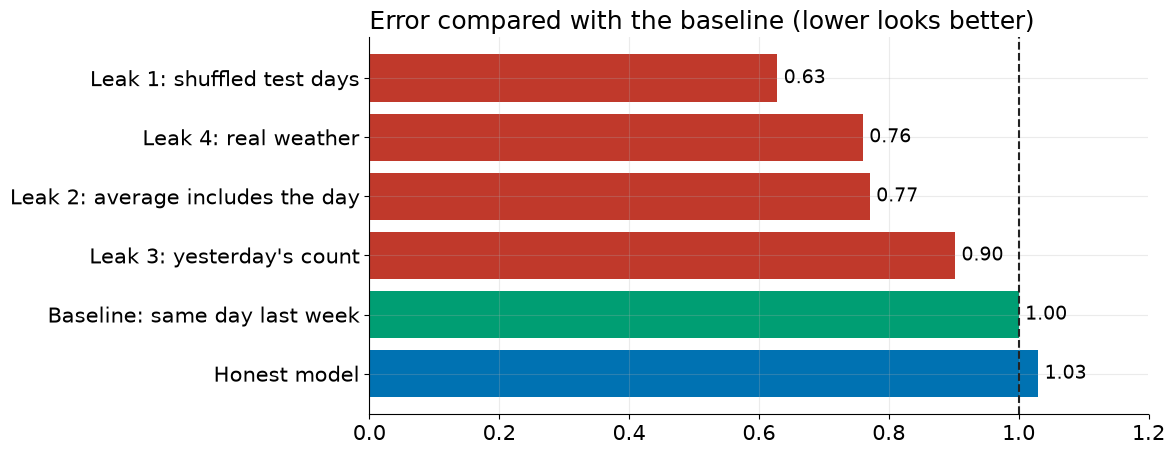

,error (bikes/day),vs baseline
Leak 1: shuffled test days,539.0,0.63
Leak 4: real weather,652.0,0.76
Leak 2: average includes the day,661.0,0.77
Leak 3: yesterday's count,774.0,0.90
Baseline: same day last week,858.0,1.00
Honest model,884.0,1.03


In [8]:
board = pd.Series(results).sort_values()
relative = board / baseline_error
colours = ["#C0392B" if name.startswith("Leak") else ("#0072B2" if name.startswith("Honest") else "#009E73")
           for name in relative.index]

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.barh(relative.index[::-1], relative.values[::-1], color=colours[::-1])
ax.axvline(1, color="#222", ls="--", lw=1.5)
for i, v in enumerate(relative.values[::-1]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=14)
ax.set(title="Error compared with the baseline (lower looks better)", xlim=(0, 1.2))
plt.tight_layout(); plt.show()

pd.DataFrame({"error (bikes/day)": board.round(0), "vs baseline": relative.round(2)})

# What the scoreboard tells us

- **Every leak turned a losing model into a "winner"**
- The **shuffled test** looks the best of all, and it is the **easiest mistake** to make
- The **only honest bar** says the model is slightly worse than the baseline

**In plain words:** if we had shipped any of the red models, we would have promised a big improvement and delivered a small loss.

# The one question that catches almost every leak

## "Would I know this, at the moment I make the forecast?"

Ask it about **every feature**, and about **how you split** the data.

- Calendar: **yes**
- Last week's bikes: **yes**
- Yesterday's bikes, a week ahead: **no**
- Tomorrow's real weather: **no**, only the forecast

# Your leakage checklist

1. **Too good to be true?** Compare with the baseline. A huge jump is a **red flag**, not a party
2. **Split by time, always.** Train on the past, test on the future. Backtest on many weeks
3. **For every feature, ask the one question:** would I know this at forecast time?
4. **Shift first, then roll.** Averages and totals must end before the forecast is made
5. **Use forecasts, not actuals,** for anything about the future: weather, prices, events

# Next episode

## I Forecast Traffic From 1,821 Road Sensors (and Broke Some on Purpose)

From one series to **thousands at once**: what changes, and what happens when sensors fail.

The code from today is linked in the description.